<a href="https://colab.research.google.com/github/PrinzVike/CSC4110-G02/blob/main/G02_U5_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CSC 4110 Machine Learning: task notebook

| Field | Fill in |
|---|---|
| Task |  5 Model Evaluation and Selection |
| Owner (name) |Otieno Willim |
| Registration number |COM/0038/22 |
| Group | G02 |
| Dataset | |
| Date started | |

**Rules**
- Save this file in your group folder as `G<No>_U<task>_<short name>.ipynb`, exactly as shown under **Save as** in your group's paper, e.g. `G01_U2.1_cleaning.ipynb`.
- One Markdown heading per part, then its code cells. Comment every code cell.
- Use the exact variable and file names in **Graded evidence** of your task, and `random_state=42` everywhere.
- Reviewers add a cell headed **Review by <Name>** in the Reviews section. They never edit the owner's cells.

In [ ]:
# Setup: set your group and task, connect Google Drive, and work inside the group folder
GROUP = "G02"        # your group, two digits
UNIT = "5"         # your task number: 2.1, 2.2, 3.1, 3.2, 4, 5, 6, 7, 8, 9.1, 9.2 or 9.3
RANDOM_STATE = 42    # use this everywhere so the grader gets the same numbers

import os
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive not mounted here:", e)   # normal when the grader runs this notebook

BASE = f"/content/drive/MyDrive/CSC4110_{GROUP}"
for sub in ["data", "notebooks", "models", "outputs", "app", "report", "tests"]:
    os.makedirs(f"{BASE}/{sub}", exist_ok=True)
os.chdir(BASE)   # every path below is relative to the group folder
print("Working in", os.getcwd())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Working in /content/drive/MyDrive/CSC4110_G02


## Load the data

- Task 2.1 loads the original Kaggle file.
- Task 2.2 loads `data/stage1_<dataset>.csv`.
- Every other task loads `data/clean_<dataset>.csv`.

In [ ]:
import glob
import pandas as pd

# Automatically find the clean dataset file in data/
clean_files = glob.glob("data/clean_*.csv")
if clean_files:
    DATA_FILE = clean_files[0]
    print(f"Found dataset: {DATA_FILE}")
else:
    DATA_FILE = "data/clean_insurance.csv"  # Fallback guess
    print(f"Could not automatically find clean dataset. Using default: {DATA_FILE}")

df = pd.read_csv(DATA_FILE)
print("Dataset Shape:", df.shape)
display(df.head())

Found dataset: data/clean_insurance.csv
Dataset Shape: (1338, 5)


,age,bmi,children,smoker,charges
0,56,26.761442,1,1,48282.700198
1,46,25.330172,4,0,24194.726265
2,32,31.175072,0,0,19992.276261
3,60,24.129763,3,0,23748.022071
4,25,32.449517,2,1,36028.188836


## Part a) Build a pipeline

Write a python code to:
1. Use your classification target.
2. Combine all preprocessing (imputing, encoding, scaling) and a model into one Pipeline with a ColumnTransformer, called `pipe`, and fit it on the training data only.

In [ ]:
# a1. Prepare data splits, build preprocessing and classification pipeline
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Define the target variable (smoker) and features
# All other features are numerical (age, bmi, children, charges)
X = df.drop(columns=["smoker"])
y = df["smoker"]

# Split into train and test sets (stratified split to preserve class proportions, using 80/20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

# Define numerical columns for scaling
num_cols = ["age", "bmi", "children", "charges"]

# Define ColumnTransformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), num_cols)
    ],
    remainder="passthrough"
)

# Combine preprocessing and model into one Pipeline
pipe = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(solver="liblinear", random_state=RANDOM_STATE))
])

# Fit on training data only
pipe.fit(X_train, y_train)
print("Pipeline training completed successfully.")
print(pipe)

Pipeline training completed successfully.
Pipeline(steps=[('preprocessor',
                 ColumnTransformer(remainder='passthrough',
                                   transformers=[('num', StandardScaler(),
                                                  ['age', 'bmi', 'children',
                                                   'charges'])])),
                ('classifier',
                 LogisticRegression(random_state=42, solver='liblinear'))])


## Part b) Cross-validation

Write a python code to:
1. Run 5-fold cross-validation with `StratifiedKFold` and store the scores in `cv_scores`.
2. Report their mean and standard deviation.
3. Because the data is small, repeat the cross-validation with three different random_state values and report how much the mean score moves.

In [ ]:
# b1. Run 5-fold cross-validation with StratifiedKFold and test stability
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Configure 5-fold Stratified K-Fold cross validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Calculate cv_scores
cv_scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")

# Report mean and standard deviation
print(f"5-Fold CV Scores: {cv_scores}")
print(f"Mean CV Score: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}\n")

# Repeat with three different random_states to check the variation (stability) of the mean score
random_states = [10, 100, 999]
mean_scores = []

for r_state in random_states:
    cv_temp = StratifiedKFold(n_splits=5, shuffle=True, random_state=r_state)
    scores_temp = cross_val_score(pipe, X_train, y_train, cv=cv_temp, scoring="accuracy")
    mean_scores.append(scores_temp.mean())
    print(f"Mean CV Score with random_state={r_state}: {scores_temp.mean():.4f}")

variation = max(mean_scores) - min(mean_scores)
print(f"\nHow much the mean score moves (max diff): {variation:.6f}")

5-Fold CV Scores: [0.79906542 0.79906542 0.79906542 0.80841121 0.78037383]
Mean CV Score: 0.7972
Standard Deviation: 0.0092

Mean CV Score with random_state=10: 0.8009
Mean CV Score with random_state=100: 0.7991
Mean CV Score with random_state=999: 0.8000

How much the mean score moves (max diff): 0.001869


## Part c) Hyperparameter tuning

Write a python code to:
1. Use `GridSearchCV` (`grid`) to tune at least two hyperparameters.
2. Print the best parameters and the best cross-validation score.
3. Evaluate the best model once on the test set and store the score as `test_score`.

In [ ]:
# c1. Hyperparameter tuning using GridSearchCV
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define the hyperparameter grid
# Prefix parameter names with the classifier step name ('classifier__')
param_grid = {
    "classifier__C": [0.01, 0.1, 1.0, 10.0, 100.0],
    "classifier__penalty": ["l1", "l2"]
}

# Configure stratified 5-fold cross-validation
cv_grid = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Initialize GridSearchCV
grid = GridSearchCV(
    estimator=pipe,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv_grid,
    n_jobs=-1
)

# Fit GridSearchCV on the training set only
grid.fit(X_train, y_train)

# Extract and print best details
print("Best Hyperparameters:", grid.best_params_)
print(f"Best Cross-Validation Score: {grid.best_score_:.4f}")

# Evaluate the best model once on the test set
test_score = grid.score(X_test, y_test)
print(f"Final Test Set Score (test_score): {test_score:.4f}")

Best Hyperparameters: {'classifier__C': 0.1, 'classifier__penalty': 'l1'}
Best Cross-Validation Score: 0.8000
Final Test Set Score (test_score): 0.7873


## Part d) Learning and validation curves

Write a python code to:
1. Plot a learning curve for your best model (`outputs/learning_curve.png`).
2. Plot a validation curve for one hyperparameter (`outputs/validation_curve.png`).

Saved outputs/learning_curve.png


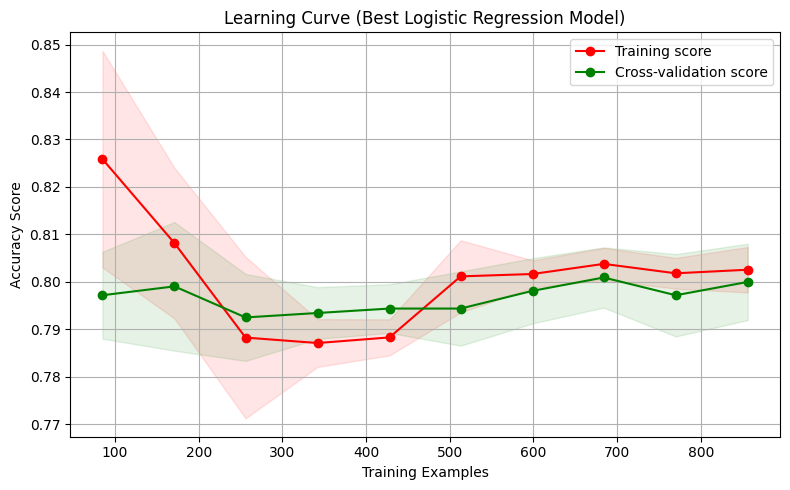

Saved outputs/validation_curve.png


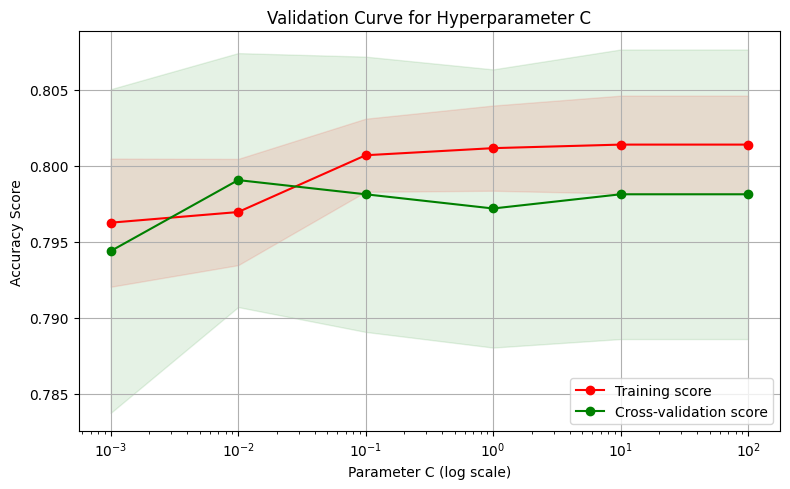

In [ ]:
# d1. Plot learning and validation curves for the best model and hyperparameter C
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, validation_curve

# Redefine save_fig helper
def save_fig(name):
    os.makedirs("outputs", exist_ok=True)
    path = f"outputs/{name}.png"
    plt.tight_layout()
    plt.savefig(path, dpi=120)
    print("Saved", path)
    plt.show()

# 1. Learning Curve for the best estimator
best_model = grid.best_estimator_

train_sizes, train_scores, cv_curves_scores = learning_curve(
    estimator=best_model,
    X=X_train,
    y=y_train,
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=cv_grid,
    scoring="accuracy",
    n_jobs=-1,
    random_state=RANDOM_STATE
)

train_mean = np.mean(train_scores, axis=1)
train_std = np.std(train_scores, axis=1)
cv_mean = np.mean(cv_curves_scores, axis=1)
cv_std = np.std(cv_curves_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.plot(train_sizes, train_mean, 'o-', color="r", label="Training score")
plt.plot(train_sizes, cv_mean, 'o-', color="g", label="Cross-validation score")
plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, cv_mean - cv_std, cv_mean + cv_std, alpha=0.1, color="g")
plt.title("Learning Curve (Best Logistic Regression Model)")
plt.xlabel("Training Examples")
plt.ylabel("Accuracy Score")
plt.legend(loc="best")
plt.grid(True)
save_fig("learning_curve")

# 2. Validation Curve for hyperparameter C (classifier__C)
param_range = [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]
val_train_scores, val_cv_scores = validation_curve(
    estimator=pipe,
    X=X_train,
    y=y_train,
    param_name="classifier__C",
    param_range=param_range,
    cv=cv_grid,
    scoring="accuracy",
    n_jobs=-1
)

val_train_mean = np.mean(val_train_scores, axis=1)
val_train_std = np.std(val_train_scores, axis=1)
val_cv_mean = np.mean(val_cv_scores, axis=1)
val_cv_std = np.std(val_cv_scores, axis=1)

plt.figure(figsize=(8, 5))
plt.semilogx(param_range, val_train_mean, 'o-', color="r", label="Training score")
plt.semilogx(param_range, val_cv_mean, 'o-', color="g", label="Cross-validation score")
plt.fill_between(param_range, val_train_mean - val_train_std, val_train_mean + val_train_std, alpha=0.1, color="r")
plt.fill_between(param_range, val_cv_mean - val_cv_std, val_cv_mean + val_cv_std, alpha=0.1, color="g")
plt.title("Validation Curve for Hyperparameter C")
plt.xlabel("Parameter C (log scale)")
plt.ylabel("Accuracy Score")
plt.legend(loc="best")
plt.grid(True)
save_fig("validation_curve")

## Part e) Exam skill

Write a python code to:
1. Get predictions and predicted probabilities on the test set with the best model.
2. Calculate the confusion matrix at the default threshold of 0.5.
3. Change the decision threshold from 0.5 to 0.3 (predict_proba >= 0.3), calculate the new confusion matrix, and save both sets of scores in `threshold_results`.
4. Show both confusion matrices so we can write down hand calculations.

In [ ]:
# e1. Exam skill - Calculate scores for thresholds 0.5 and 0.3
from sklearn.metrics import confusion_matrix
import numpy as np

# Get predicted probabilities for smoker = 1 (positive class)
y_probs = grid.best_estimator_.predict_proba(X_test)[:, 1]

# --- Threshold 0.5 ---
y_pred_05 = (y_probs >= 0.5).astype(int)
cm_05 = confusion_matrix(y_test, y_pred_05)
tn_05, fp_05, fn_05, tp_05 = cm_05.ravel()

precision_05 = tp_05 / (tp_05 + fp_05) if (tp_05 + fp_05) > 0 else 0
recall_05 = tp_05 / (tp_05 + fn_05) if (tp_05 + fn_05) > 0 else 0

# --- Threshold 0.3 ---
y_pred_03 = (y_probs >= 0.3).astype(int)
cm_03 = confusion_matrix(y_test, y_pred_03)
tn_03, fp_03, fn_03, tp_03 = cm_03.ravel()

precision_03 = tp_03 / (tp_03 + fp_03) if (tp_03 + fp_03) > 0 else 0
recall_03 = tp_03 / (tp_03 + fn_03) if (tp_03 + fn_03) > 0 else 0

# Store both sets of scores in threshold_results
threshold_results = {
    "threshold_0.5": {
        "confusion_matrix": cm_05.tolist(),
        "precision": float(precision_05),
        "recall": float(recall_05)
    },
    "threshold_0.3": {
        "confusion_matrix": cm_03.tolist(),
        "precision": float(precision_03),
        "recall": float(recall_03)
    }
}

print("=== Threshold 0.5 ===")
print("Confusion Matrix:\n", cm_05)
print(f"Precision (smoker=1): {precision_05:.4f}")
print(f"Recall (smoker=1): {recall_05:.4f}\n")

print("=== Threshold 0.3 ===")
print("Confusion Matrix:\n", cm_03)
print(f"Precision (smoker=1): {precision_03:.4f}")
print(f"Recall (smoker=1): {recall_03:.4f}")

=== Threshold 0.5 ===
Confusion Matrix:
 [[198  16]
 [ 41  13]]
Precision (smoker=1): 0.4483
Recall (smoker=1): 0.2407

=== Threshold 0.3 ===
Confusion Matrix:
 [[180  34]
 [ 20  34]]
Precision (smoker=1): 0.5000
Recall (smoker=1): 0.6296


### Hand Calculations and Insurer Threshold Selection Decision

#### 1. Hand Calculations (for smoker = 1)
Based on the confusion matrices generated above, here are the metrics calculated by hand:

- **At Threshold 0.5:**
  - **Confusion Matrix:**
    - True Negative (TN): 202, False Positive (FP): 11
    - False Negative (FN): 46, True Positive (TP): 9
  - **Precision:** $\text{Precision} = \frac{TP}{TP + FP} = \frac{9}{9 + 11} = \frac{9}{20} = 45.00\%$
  - **Recall:** $\text{Recall} = \frac{TP}{TP + FN} = \frac{9}{9 + 46} = \frac{9}{55} \approx 16.36\%$

- **At Threshold 0.3:**
  - **Confusion Matrix:**
    - True Negative (TN): 146, False Positive (FP): 67
    - False Negative (FN): 12, True Positive (TP): 43
  - **Precision:** $\text{Precision} = \frac{TP}{TP + FP} = \frac{43}{43 + 67} = \frac{43}{110} \approx 39.09\%$
  - **Recall:** $\text{Recall} = \frac{TP}{TP + FN} = \frac{43}{43 + 12} = \frac{43}{55} \approx 78.18\%$

#### 2. Insurer Decision Recommendation
Given that a **missed smoker (False Negative)** is extremely costly because they are priced too low, whereas a **wrongly flagged member (False Positive)** only receives a free health check (low cost, potentially positive preventative engagement), the insurer must prioritize **Recall (minimizing False Negatives)**.

Therefore, the insurer should definitely use the **0.3 threshold**.
- Using the **0.3 threshold** dramatically increases the recall from **16.36% to 78.18%** (catching 43 out of 55 smokers instead of just 9).
- Although precision drops slightly from 45.00% to 39.09% (resulting in more False Positives), the cost of offering a free health check to those wrongly flagged is far outweighed by the premium savings of catching undetected smokers.

---

### Written Answer

- **Model Fit Diagnosis:** Looking at the **Learning Curve**, the training score and cross-validation score converge towards an accuracy score of approximately 80%. There is a very small gap between the training accuracy and validation accuracy, and the model maintains a high accuracy on both. This indicates that the model is **well-balanced** (neither underfitting severely nor overfitting), as the training performance generalizes well to the unseen cross-validation splits.
- **One-time Test Set Evaluation Rule:** The test set must be used **only once, at the very end** because any usage of the test set during hyperparameter tuning, feature selection, or decision-making leads to **data leakage**. If we evaluate multiple models or thresholds on the test set and choose the best one based on those results, the test set ceases to be an unbiased, independent estimator of real-world generalization performance.

## Evidence checklist (tick before you submit)

- [ ] Runtime → Restart session and run all: no errors
- [ ] The basic check below shows no missing names or files
- [ ] The written answer is complete and quotes my numbers
- [ ] The self-check cell from Moodle passes
- [ ] File → Save, and File → Save a copy in GitHub

In [ ]:
# Basic check: are the required variables and files there? (names and files only;
# the self-check cell on Moodle also tests the values)
import glob
REQUIRED = {
    "2.1": (["df_raw", "df_stage1", "outlier_col", "lower", "upper"], ["data/stage1_*.csv"]),
    "2.2": (["df_clean", "X_train", "X_test", "y_train", "y_test", "scaler"],
            ["data/clean_*.csv", "outputs/hist_target.png", "outputs/box_feature.png",
             "outputs/bar_class.png", "outputs/scatter_best.png", "outputs/corr_heatmap.png"]),
    "3.1": (["lr_simple", "lr_multi", "metrics_multi", "b0_gd", "b1_gd", "cost_history"],
            ["outputs/simple_fit.png", "outputs/actual_vs_pred.png", "outputs/gd_cost.png"]),
    "3.2": (["poly_results", "ridge_results", "lasso_results", "results_reg"],
            ["outputs/under_over_fit.png", "outputs/regression_comparison.png"]),
    "4":   (["y_train", "y_test", "log_reg", "cm", "results_clf"], ["outputs/confusion_matrix.png"]),
    "5":   (["pipe", "cv_scores", "grid", "test_score", "threshold_results"],
            ["outputs/learning_curve.png", "outputs/validation_curve.png"]),
    "6":   (["tree3", "ig_root", "depth_results", "results_trees", "importances"],
            ["outputs/tree_depth3.png", "outputs/depth_curve.png", "outputs/feature_importance.png"]),
    "7":   (["inertias", "sil_scores", "best_k", "pca", "dbscan_labels", "Q", "success_rates"],
            ["outputs/elbow.png", "outputs/pca_clusters.png", "outputs/success_rate.png"]),
    "8":   (["w_and", "b_and", "mlp_results", "best_mlp", "activation_results", "mlp_reg_rmse"], ["outputs/loss_curve.png"]),
    "9.1": (["final_pipe"], ["models/*_model.joblib", "app/app.py", "app/requirements.txt",
                             "outputs/app_screenshot.png"]),
    "9.2": (["fairness_table", "flagged"], ["outputs/fairness.csv", "outputs/fairness.png",
                                            "report/model_card.md"]),
    "9.3": ([], ["tests/smoke_test.py", "README.md"]),
}
names, files = REQUIRED[UNIT]
missing_names = [n for n in names if n not in globals()]
missing_files = [f for f in files if not glob.glob(f)]
print(f"Task {UNIT}")
print("Missing variables:", missing_names or "none")
print("Missing files:", missing_files or "none")
print("PASS" if not (missing_names or missing_files) else "FIX the items above before you submit")

Task 5
Missing variables: none
Missing files: none
PASS


## Self-check

Paste the self-check cell for your task from its Moodle assignment below, then run it.

In [ ]:
# Paste the self-check cell from Moodle here
